# Data analysis

Look at the data and try to find out why models fail.

Analyze at least the following:
- distributions of sampled parameters
- distributions of div_u_star
- xy plot of div_u_star vs phi
- mean of div_u_star per spatial point
- some direct plots of div_u_star and their solutions
- how do we find outliers?

In [2]:
import numpy as np
import os
import sys
import json
from tqdm import tqdm
import matplotlib.pyplot as plt
from data import geometry_to_mtx

sys.path.append("..")
from derivatives import laplacian

In [3]:
DATA_PATH = "../../../data"

div_u_star = []
phi = []
u_star = []
params = []
boundary_mask = []

for i in tqdm(range(0, 100)):
    dus = np.load(os.path.join(DATA_PATH, str(i), "div_u_star.npy"))
    div_u_star.append(dus)

    us = np.load(os.path.join(DATA_PATH, str(i), "u_star.npy"))
    u_star.append(us)

    p = np.load(os.path.join(DATA_PATH, str(i), "phi.npy"))
    phi.append(p)

    with open(os.path.join(DATA_PATH, str(i), "params.json")) as f:
        prms = json.load(f)
    params.append(prms)

    _, _, _, _, _, _, bm = geometry_to_mtx(prms["geometry"], 64, 64)
    boundary_mask.append(bm)

div_u_star = np.array(div_u_star)
u_star = np.array(u_star)
phi = np.array(phi)
boundary_mask = np.array(boundary_mask)

100%|██████████| 100/100 [00:01<00:00, 94.19it/s]


## General stats

### Div u star

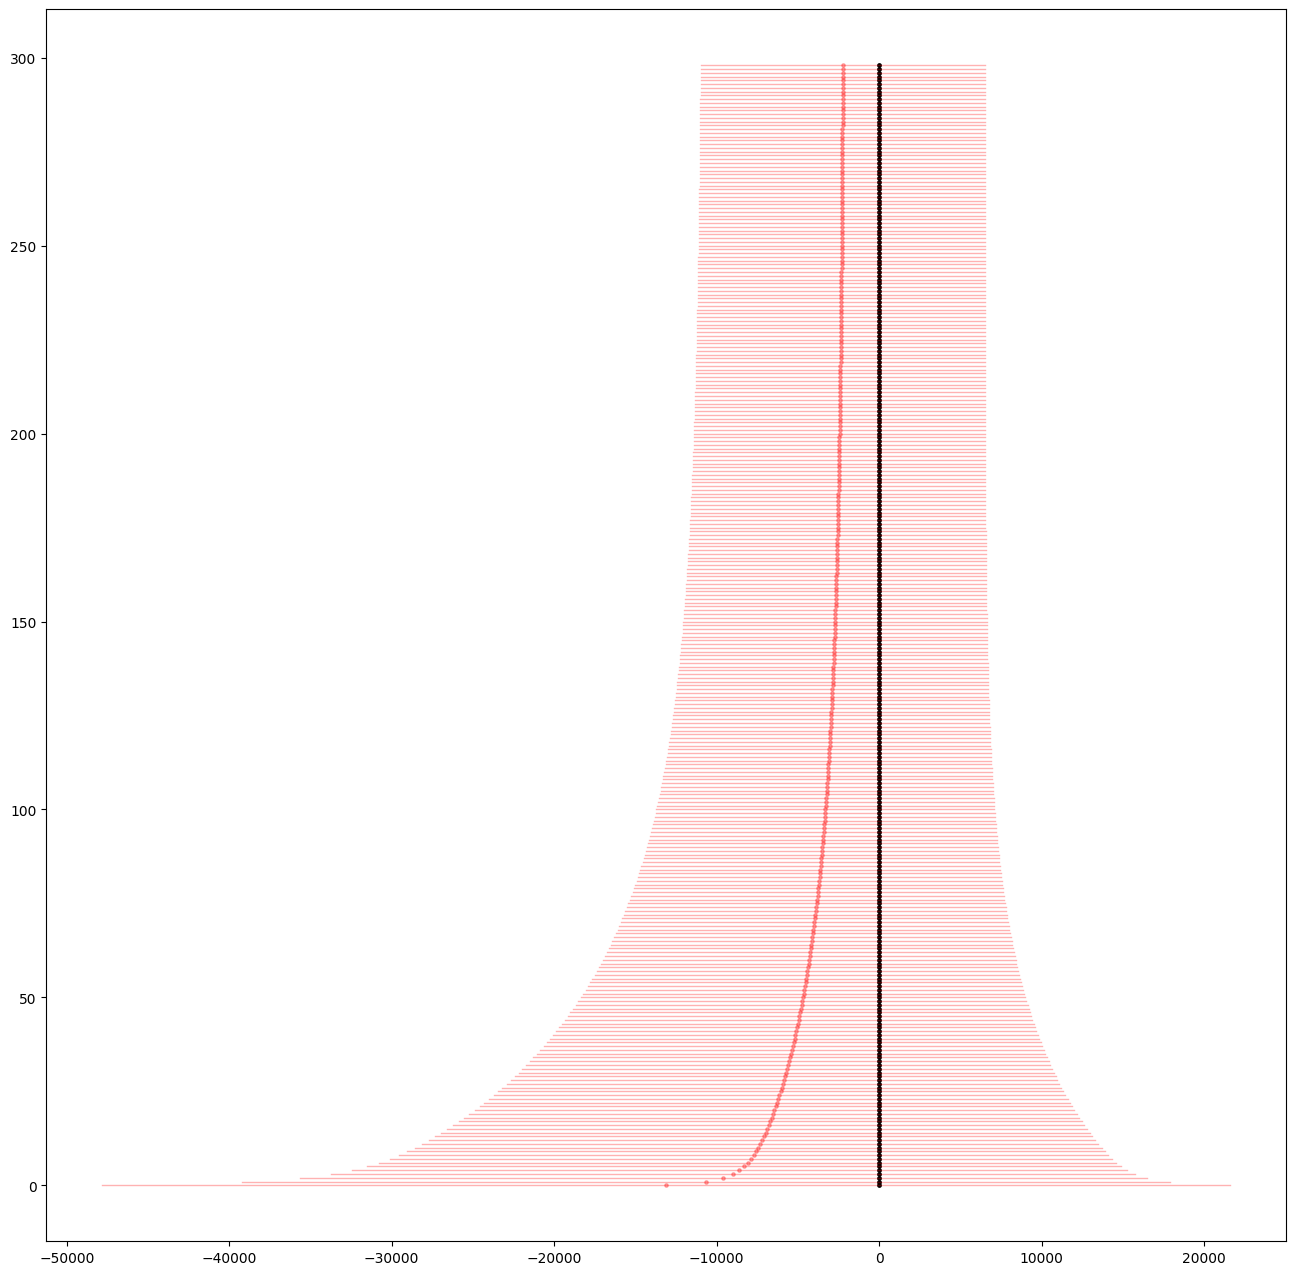

In [29]:
fig, ax = plt.subplots(figsize=(16, 16), nrows=1, ncols=1)
# ax = ax.flatten()
dus_all = []

for i in range(0, 299):
    dus_mean = []
    dus_mean_nb = []
    for case_i in range(0, 100):
        dus_mean.append(div_u_star[case_i, i].mean())
        dus_mean_nb.append((div_u_star[case_i, i] * (1 - boundary_mask[case_i])).mean())

    mn = np.mean(dus_mean)
    sd = np.std(dus_mean)

    mnnb = np.mean(dus_mean_nb)
    sdnb = np.std(dus_mean_nb)

    ax.scatter(mn, i, color="black", s=6)
    ax.plot([mn - sd, mn + sd], [i, i], color="black")

    ax.scatter(mnnb, i, color="red", s=6, alpha=0.3)
    ax.plot([mnnb - sdnb, mnnb + sdnb], [i, i], color="red", alpha=0.3, linewidth=1)


    # dus_mean = np.array(dus_mean)

    # ax.scatter(dus_mean, np.array([i for i in range(0, 299)]), marker=".", s=6)

plt.show()

The boundary holds values that drag the whole distribution to 0.

i = 0: abs(mean(no boundary)) - abs(mean(boundary)) = 0.0
i = 20: abs(mean(no boundary)) - abs(mean(boundary)) = 0.0
i = 40: abs(mean(no boundary)) - abs(mean(boundary)) = -9.094947017729282e-13
i = 60: abs(mean(no boundary)) - abs(mean(boundary)) = 0.0
i = 80: abs(mean(no boundary)) - abs(mean(boundary)) = 0.0
i = 100: abs(mean(no boundary)) - abs(mean(boundary)) = -4.547473508864641e-13
i = 120: abs(mean(no boundary)) - abs(mean(boundary)) = 0.0
i = 140: abs(mean(no boundary)) - abs(mean(boundary)) = 0.0
i = 160: abs(mean(no boundary)) - abs(mean(boundary)) = 0.0
i = 180: abs(mean(no boundary)) - abs(mean(boundary)) = 0.0
i = 200: abs(mean(no boundary)) - abs(mean(boundary)) = 0.0
i = 220: abs(mean(no boundary)) - abs(mean(boundary)) = 0.0
i = 240: abs(mean(no boundary)) - abs(mean(boundary)) = 0.0
i = 260: abs(mean(no boundary)) - abs(mean(boundary)) = 4.547473508864641e-13
i = 280: abs(mean(no boundary)) - abs(mean(boundary)) = 4.547473508864641e-13


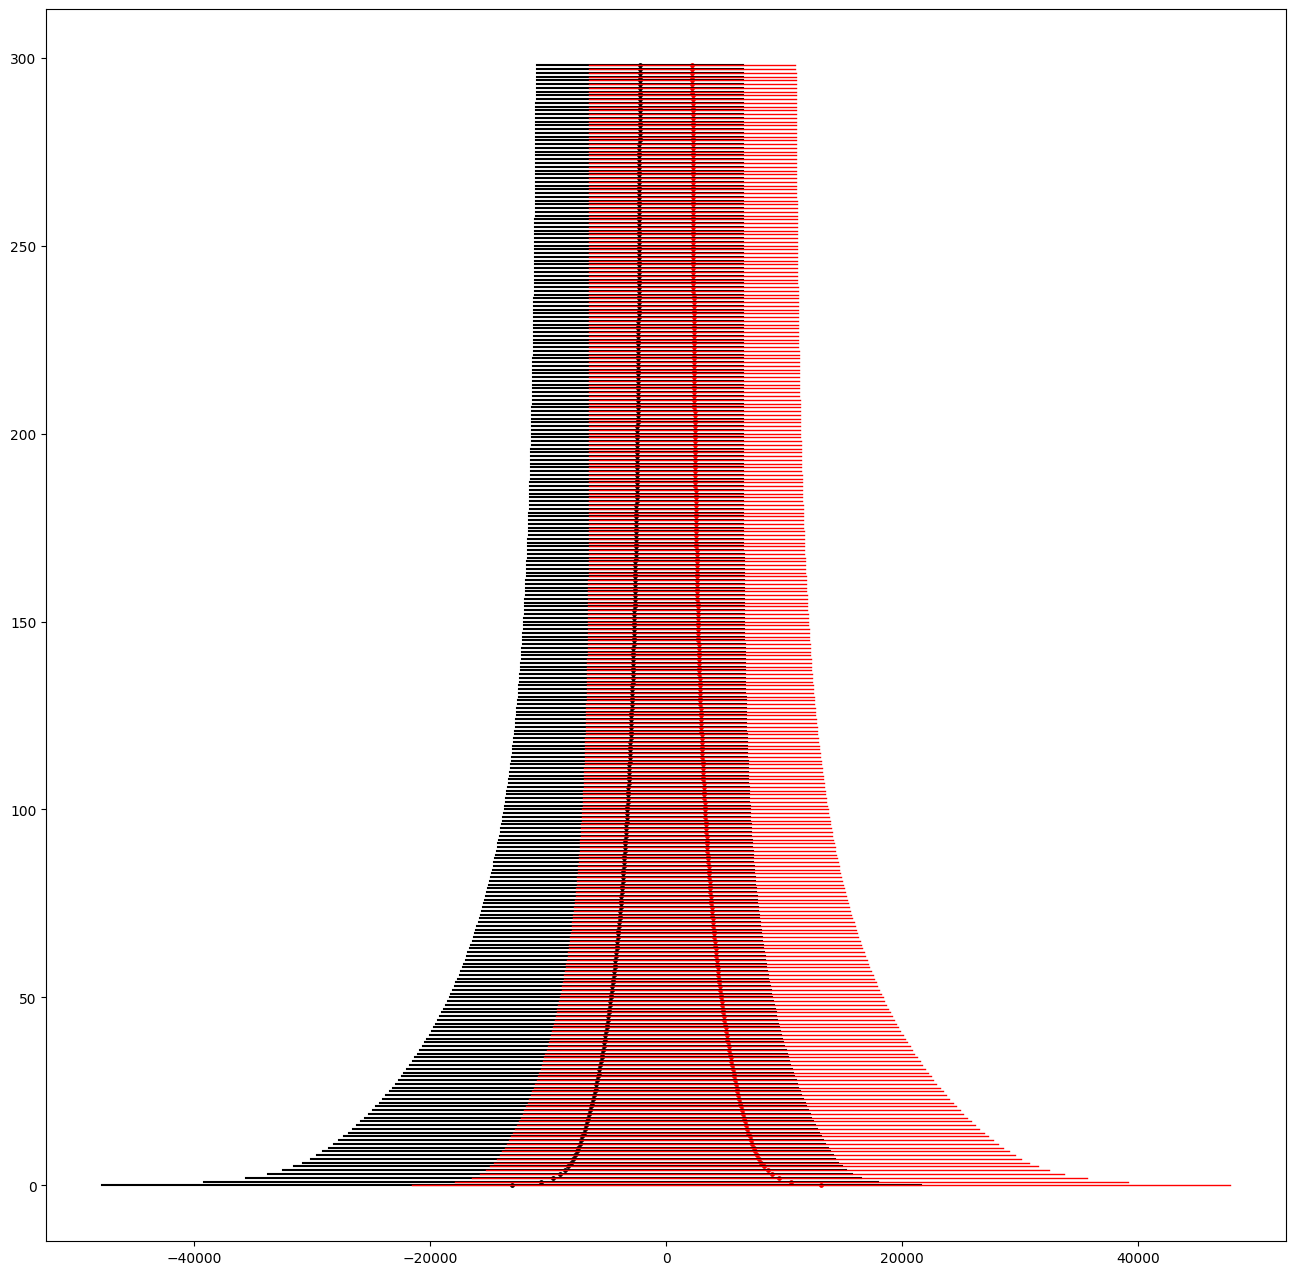

In [44]:
fig, ax = plt.subplots(figsize=(16, 16), nrows=1, ncols=1)
# ax = ax.flatten()
dus_all = []

for i in range(0, 299):
    dus_mean = []
    dus_mean_nb = []
    for case_i in range(0, 100):
        dus_mean.append((div_u_star[case_i, i] * (1 - boundary_mask[case_i])).mean())
        dus_mean_nb.append((div_u_star[case_i, i] * boundary_mask[case_i]).mean())

    mn = np.mean(dus_mean)
    sd = np.std(dus_mean)

    mnnb = np.mean(dus_mean_nb)
    sdnb = np.std(dus_mean_nb)

    ax.scatter(mn, i, color="black", s=6)
    ax.plot([mn - sd, mn + sd], [i, i], color="black")

    ax.scatter(mnnb, i, color="red", s=6)
    ax.plot([mnnb - sdnb, mnnb + sdnb], [i, i], color="red", linewidth=1)

    if i % 20 == 0:
        print(f"i = {i}: abs(mean(no boundary)) - abs(mean(boundary)) = {(np.abs(mn) - np.abs(mnnb))}")


    # dus_mean = np.array(dus_mean)

    # ax.scatter(dus_mean, np.array([i for i in range(0, 299)]), marker=".", s=6)

plt.show()

Boundary values are large and definately not near 0. 
Also: we can see that in each iteration the boundary values and the non-boundary values are exact reverses of each other.

### Phi

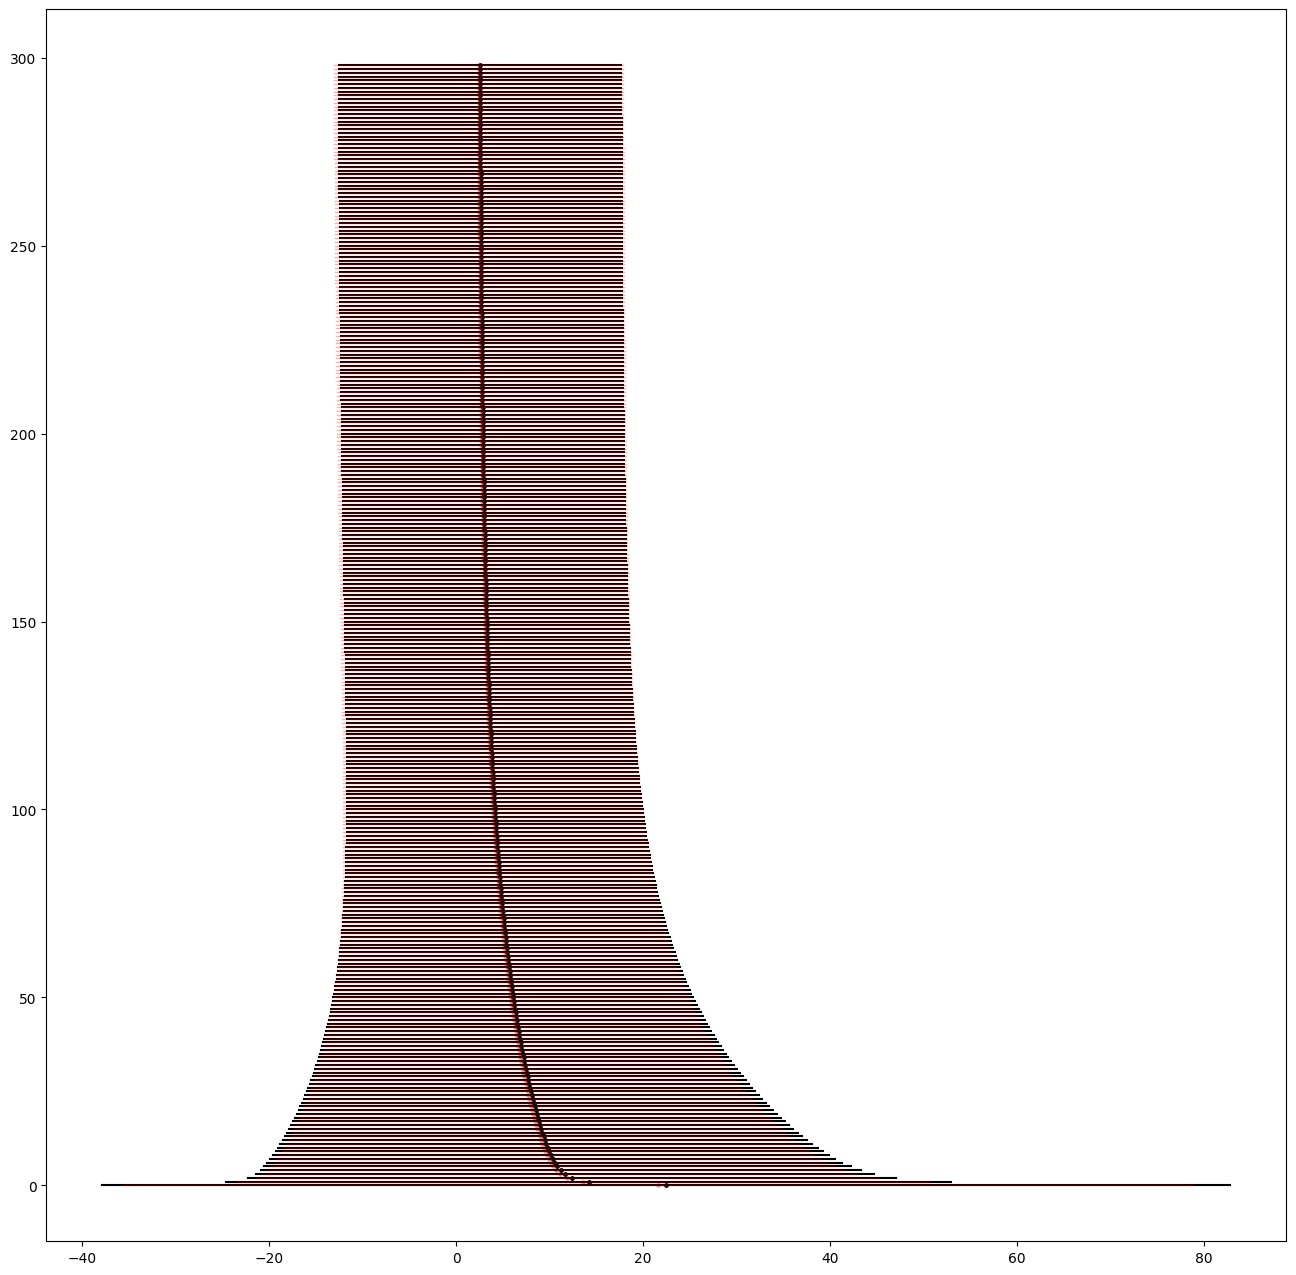

In [30]:
fig, ax = plt.subplots(figsize=(16, 16), nrows=1, ncols=1)
# ax = ax.flatten()
dus_all = []

for i in range(0, 299):
    dus_mean = []
    dus_mean_nb = []
    for case_i in range(0, 100):
        dus_mean.append(phi[case_i, i].mean())
        dus_mean_nb.append((phi[case_i, i] * (1 - boundary_mask[case_i])).mean())

    mn = np.mean(dus_mean)
    sd = np.std(dus_mean)

    mnnb = np.mean(dus_mean_nb)
    sdnb = np.std(dus_mean_nb)

    ax.scatter(mn, i, color="black", s=6)
    ax.plot([mn - sd, mn + sd], [i, i], color="black")

    ax.scatter(mnnb, i, color="red", s=6, alpha=0.3)
    ax.plot([mnnb - sdnb, mnnb + sdnb], [i, i], color="red", alpha=0.3, linewidth=1)


    # dus_mean = np.array(dus_mean)

    # ax.scatter(dus_mean, np.array([i for i in range(0, 299)]), marker=".", s=6)

plt.show()

For Phi on the other hand, the distribution with or without boundaries is basically the same. This means that the numeric method for solving the pressure Poisson equation produces a result that has relatively "stable" boundaries (similar to other points) and the PINN should do the same.

### Laplacian of Phi

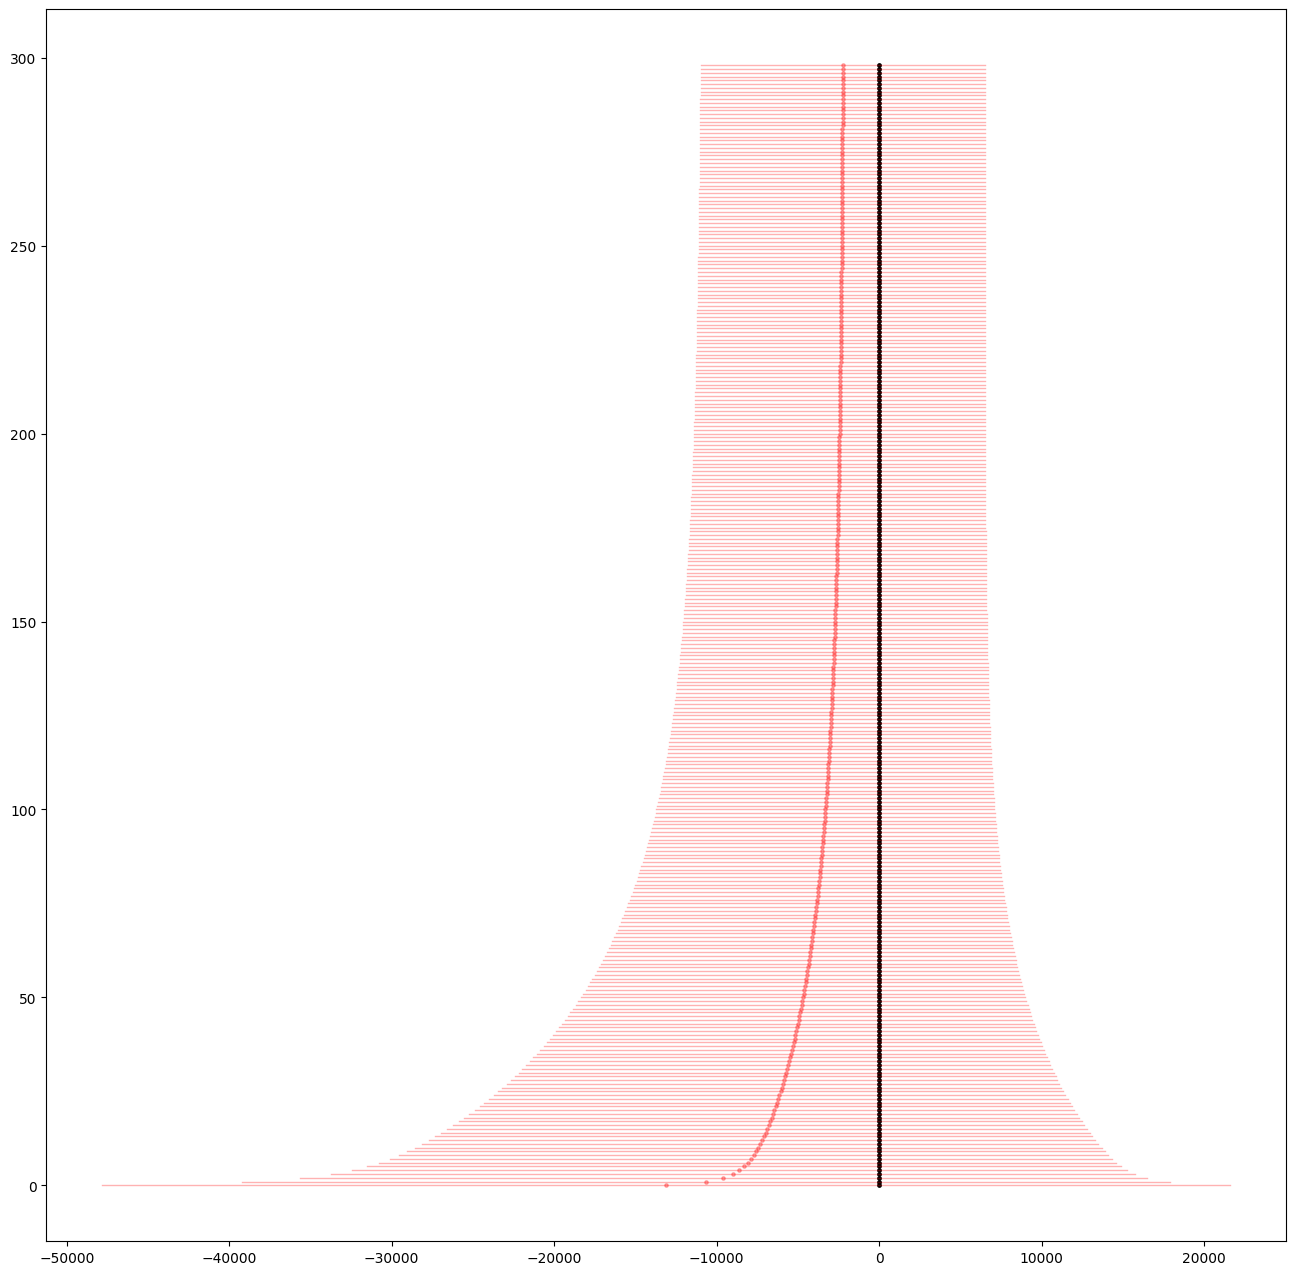

In [32]:
fig, ax = plt.subplots(figsize=(16, 16), nrows=1, ncols=1)
# ax = ax.flatten()
dus_all = []

for i in range(0, 299):
    dus_mean = []
    dus_mean_nb = []
    for case_i in range(0, 100):
        lap_p = laplacian(phi[case_i, i],
                      dx = params[case_i]["dx"],
                      dy = params[case_i]["dy"],
                      boundary=boundary_mask[case_i],
                      numpy_=True)

        dus_mean.append(lap_p.mean())
        dus_mean_nb.append((lap_p * (1 - boundary_mask[case_i])).mean())

    mn = np.mean(dus_mean)
    sd = np.std(dus_mean)

    mnnb = np.mean(dus_mean_nb)
    sdnb = np.std(dus_mean_nb)

    ax.scatter(mn, i, color="black", s=6)
    ax.plot([mn - sd, mn + sd], [i, i], color="black")

    ax.scatter(mnnb, i, color="red", s=6, alpha=0.3)
    ax.plot([mnnb - sdnb, mnnb + sdnb], [i, i], color="red", alpha=0.3, linewidth=1)


    # dus_mean = np.array(dus_mean)

    # ax.scatter(dus_mean, np.array([i for i in range(0, 299)]), marker=".", s=6)

plt.show()

For Laplacian of Phi its the same thing as with div u star - the boundary really changes the distribution.

## Per-sample analysis

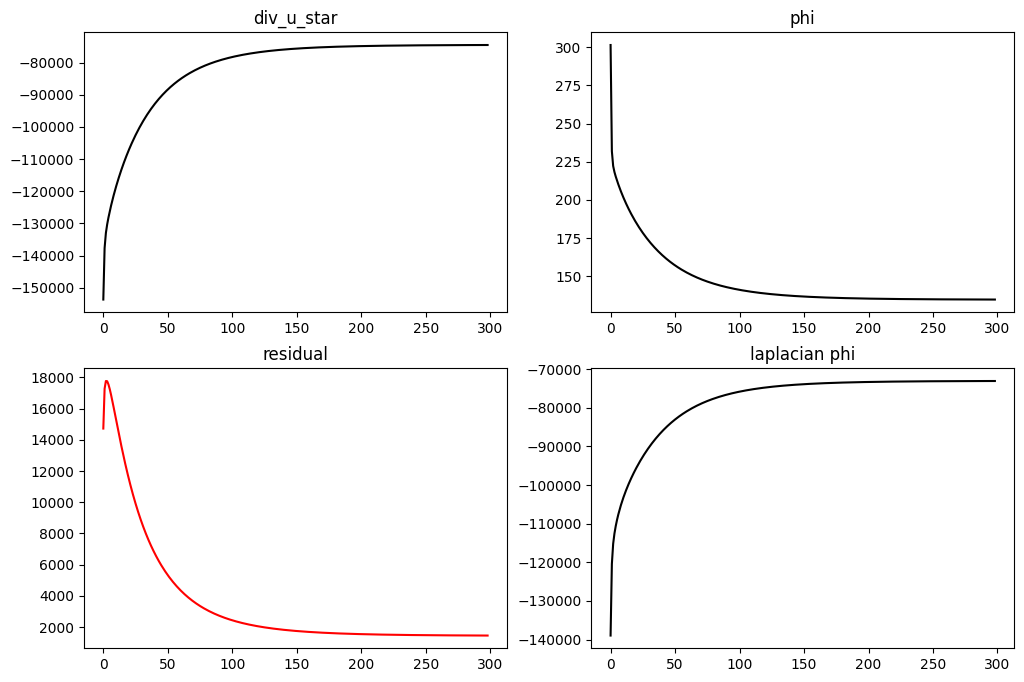

In [25]:
case_i = 10

dmean = []
dstd = []

pmean = []
pstd = []

lapmean = []
lapstd = []

resmean = []
resstd = []

for i in range(0, 299):
    b = 1 - boundary_mask[case_i]
    dus = div_u_star[case_i, i]
    p = phi[case_i, i]

    lap_p = laplacian(p,
                      dx = params[case_i]["dx"],
                      dy = params[case_i]["dy"],
                      boundary=b,
                      numpy_=True)

    res = lap_p - dus

    dus *= b
    p *= b
    res *= b
    lap_p *= b

    dmean.append(dus.mean())
    dstd.append(dus.std())

    pmean.append(p.mean())
    pstd.append(p.std())

    lapmean.append(lap_p.mean())
    lapstd.append(lap_p.std())

    resmean.append(res.mean())
    resstd.append(res.std())

dmean = np.array(dmean)
pmean = np.array(pmean)

fig, ax = plt.subplots(figsize=(12, 8), nrows=2, ncols=2)
ax = ax.flatten()

ax[0].plot(dmean, color="black")
# ax[0].fill_between(range(len(dmean)), dmean - dstd, dmean + dstd, color="black", alpha=0.3)

ax[1].plot(pmean, color="black")
# ax[1].fill_between(range(len(pmean)), pmean - pstd, pmean + pstd, color="black", alpha=0.3)

ax[2].plot(resmean, color="red")
# ax[2].fill_between(range(len(resmean)), resmean - resstd, resmean + resstd, color="black", alpha=0.3)

ax[3].plot(lapmean, color="black")
# ax[3].fill_between(range(len(lapmean)), lapmean - lapstd, lapmean + lapstd, color="black", alpha=0.3)

ax[0].set_title("div_u_star")
ax[1].set_title("phi")
ax[2].set_title("residual")
ax[3].set_title("laplacian phi")
plt.show()

## Images

### One case, all time steps

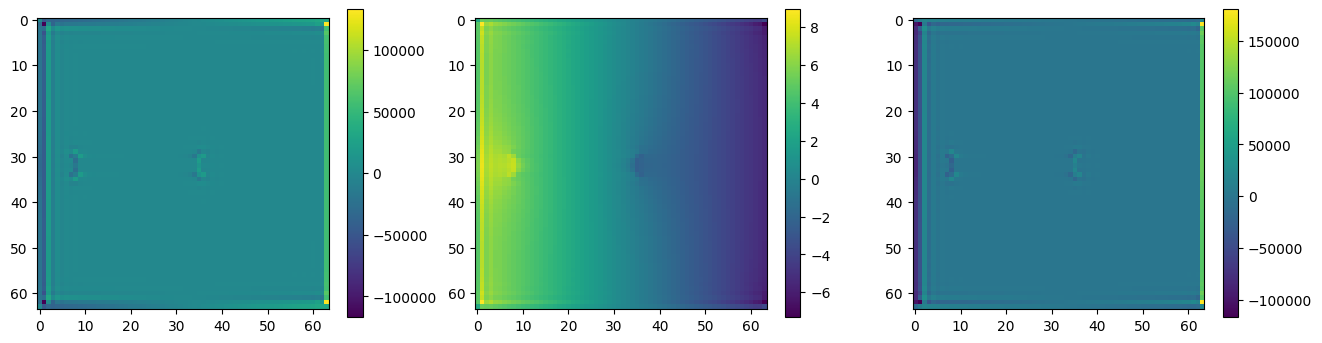

In [70]:
case_i = 20

lap_phi = np.array([laplacian(phi[case_i, i],
                      dx = params[case_i]["dx"],
                      dy = params[case_i]["dy"],
                      boundary=boundary_mask[case_i],
                      numpy_=True) for i in range(0, 299)])


fig, ax = plt.subplots(1, 3, figsize=(16, 4))
im0 = ax[0].imshow(div_u_star[case_i].mean(axis=0))
im1 = ax[1].imshow(phi[case_i].mean(axis=0))
im2 = ax[2].imshow(lap_phi.mean(axis=0))
plt.colorbar(im0)
plt.colorbar(im1)
plt.colorbar(im2)
plt.show()

### All cases, one time step

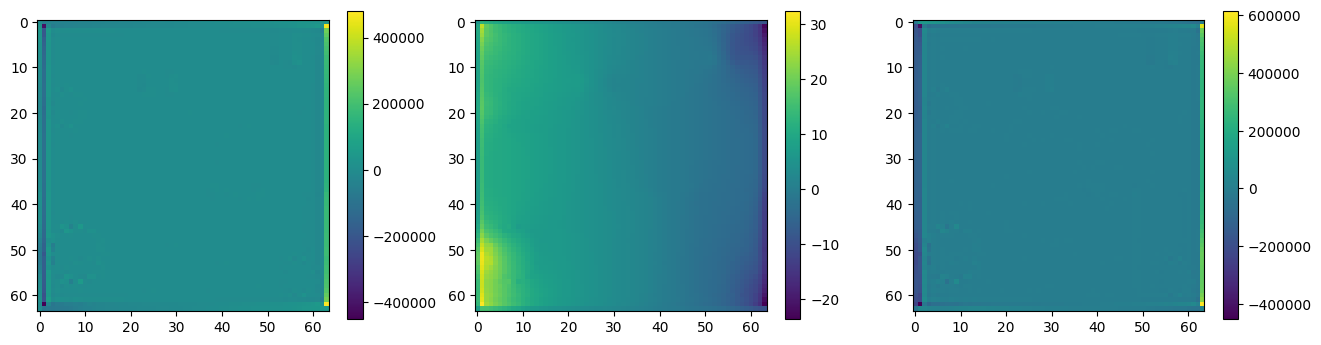

In [73]:
time_i = 200

lap_phi = np.array([laplacian(phi[i, time_i],
                      dx = params[i]["dx"],
                      dy = params[i]["dy"],
                      boundary=boundary_mask[i],
                      numpy_=True) for i in range(0, 100)])


fig, ax = plt.subplots(1, 3, figsize=(16, 4))
im0 = ax[0].imshow(div_u_star[:, time_i].mean(axis=0))
im1 = ax[1].imshow(phi[:, time_i].mean(axis=0))
im2 = ax[2].imshow(lap_phi.mean(axis=0))
plt.colorbar(im0)
plt.colorbar(im1)
plt.colorbar(im2)
plt.show()

## Conclusions

- Figure out how to handle boundaries in the input and output of the PINN. If they change the distributions this much they will definately also change the model.
- Figure out why is the mean of boundary values basically the same as the mean of non-boundary values in absolute value.
- For all cases: there is a very low divergence right next to the inflow -> fluid is flowing into points but they are not "taking it", and a very large divergence at the outflow -> fluid wants to flow out ot the domain but can't. These two divergences get a bit smaller as time goes on, but they are not perfect. Figure out why. Does this affect the model?